# Tutorial name

## Objectives Summary



## Declaring a model Component and run it

Example of a Functional component for water transport.


Imports below are necessary to implement components, and they will be repeated below so that their purpose is readable.

In [1]:
from dataclasses import dataclass

import numpy as np
import pandas as pd

from openalea.metafspm.coupling.component import (FunctionalComponent, input_variable, parameter, state_variable)
from openalea.metafspm.data_structure.configs import ScalesConfig as scales
from openalea.metafspm.solve.decorator import (boundary_condition, edge_law, graph_output, graph_system,
                                               node_balance, rate)
from openalea.metafspm.solve.solver import NewtonSolver

Toy model example

Start by inheriting from a FunctionalComponent or a StructuralComponent

In [2]:
from dataclasses import dataclass
from openalea.metafspm.coupling.component import FunctionalComponent

@dataclass
class ToyModel(FunctionalComponent):
    pass

Then declare the toy model's inputs, parameters and state variables (outputs) as dataclass fields.
When a component is declared on a Multiscale Plant Graph (the most common case when implementing a FSPM), you will need to mention a scale to anchor the declaration.
Here the toy model lives on the Compartments, the finest nodes of the plant graph.

Fill in mandatory metadata, so that the model is reusable and readable.

In [3]:
from openalea.metafspm.coupling.component import (input_variable, parameter, state_variable)
from openalea.metafspm.data_structure.configs import ScalesConfig as scales

@dataclass
class ToyModel(FunctionalComponent):
    example_input: float = input_variable(unit="MPa", unit_comment="", initialize=0.5, by="OtherToyModel", scale=scales.Compartment,
                                          min_value=0., max_value=1., description="description of example input",
                                          value_comment="", references="", DOI=[])
    example_parameter: float = parameter(unit="s-1", unit_comment="", default=2., by="ToyModel",
                                         min_value=0., max_value=10., description="description of example parameter",
                                         value_comment="", references="", DOI=[])
    example_output: float = state_variable(unit="MPa s-1", unit_comment="", initialize=0., scale=scales.Compartment,
                                           state_variable_type="intensive", min_value=0., max_value=10.,
                                           description="description of example output",
                                           value_comment="", references="", DOI=[])

Write a differential equation from this declaration, here with the example of a simple toy flow solved as a direct formula evaluation, simply using the @rate decorator.

The method's name is the variable it computes, with a leading underscore (`_example_output` computes `example_output`).
Its arguments are the variables it reads, inputs and parameters alike: metafspm passes them as whole arrays, one value per Compartment.

In [4]:
from openalea.metafspm.solve.decorator import rate

@dataclass
class ToyModel(FunctionalComponent):
    example_input: float = input_variable(unit="MPa", unit_comment="", initialize=0.5, by="OtherToyModel", scale=scales.Compartment,
                                          min_value=0., max_value=1., description="description of example input",
                                          value_comment="", references="", DOI=[])
    example_parameter: float = parameter(unit="s-1", unit_comment="", default=2., by="ToyModel",
                                         min_value=0., max_value=10., description="description of example parameter",
                                         value_comment="", references="", DOI=[])
    example_output: float = state_variable(unit="MPa s-1", unit_comment="", initialize=0., scale=scales.Compartment,
                                           state_variable_type="intensive", min_value=0., max_value=10.,
                                           description="description of example output",
                                           value_comment="", references="", DOI=[])

    @rate
    def _example_output(self, example_input, example_parameter):
        return example_parameter * example_input

Just a simple example, but that's it, you've created your first metafspm component. To run it, pass it a MetaFSPM data structure and its time step to instantiate it, then call it.

The data structure needs a plant to hold the Compartments. We build one seedling with `SeedlingStructure`, an already implemented structural component detailed further below.

In [5]:
from openalea.metafspm.data_structure.data_api import MPGDataStructure
from openalea.metafspm.scene.population import build_population
from components import SeedlingStructure

one_seedling = pd.DataFrame([dict(x=0., y=0., z=0., rotation=0., scenario={"parameters": {}})])
g, plants = build_population(one_seedling, initiators=(SeedlingStructure,))   # the plant graph (an MPG)
g.convert_properties_to_arraydict()
data_structure = MPGDataStructure(g, from_scale=g.scales.SubOrgan, nodes="Compartment")

toy_model_instance = ToyModel(data_structure=data_structure, time_step=1)
toy_model_instance()

print(f"{len(data_structure.get('example_output'))} Compartments, example_output = "
      f"{data_structure.get('example_output')[:5]} ...")

180 Compartments, example_output = [1. 1. 1. 1. 1.] ...


A more realistic toy model for plant water uptake is presented below. It uses a more advanced wrapping of the equation system as a @graph_system so that MetaFSPM solves on a plant data structure accounting for plant architecture.

Every field carries its full metadata: unit, description, plausible bounds and references.

In [6]:
@dataclass
class PlantWaterTransport(FunctionalComponent):
    """
    The water flow in the plants, on their anatomies: the Compartments are the nodes, the Connections (radial edges
    and axial junctions) the edges. Water enters at the root epidermis from the soil and leaves at the stomatal
    cavities to the air.
    """
    water_potential: float = state_variable(unit="MPa", unit_comment="", description="Water potential of a Compartment.",
                                            min_value=-10., max_value=0., value_comment="", references="", DOI=[],
                                            initialize=-0.1, scale=scales.Compartment, state_variable_type="intensive")
    water_flux: float = state_variable(unit="mm3 s-1", unit_comment="",
                                       description="Flux through a Connection, from n_id_a to n_id_b.",
                                       min_value=-1., max_value=1., value_comment="", references="", DOI=[],
                                       initialize=0., scale=scales.Connection, state_variable_type="extensive")
    conductance: float = input_variable(unit="mm3 s-1 MPa-1", unit_comment="",
                                        description="Hydraulic conductance of a Connection.",
                                        min_value=0., max_value=1e3, value_comment="", references="", DOI=[],
                                        by="SeedlingStructure", initialize=0., scale=scales.Connection,
                                        state_variable_type="intensive")
    air_water_potential: float = parameter(unit="MPa", unit_comment="",
                                           description="Water potential of the air (a constant input).",
                                           min_value=-200., max_value=0., value_comment="(R T / V_w) ln RH at 50 % relative humidity and 20 °C",
                                           references="", DOI=[], by="PlantWaterTransport", default=-93.85)
    vapour_conductance: float = input_variable(unit="mm3 s-1 MPa-1", unit_comment="",
                                               description="Liquid-vapour conductance of a stomatal cavity.",
                                               min_value=0., max_value=1., value_comment="", references="", DOI=[],
                                               by="SeedlingStructure", initialize=0., scale=scales.Compartment,
                                               state_variable_type="intensive")
    is_evaporating: float = input_variable(unit="-", unit_comment="", description="1 at the stomatal cavities.",
                                           min_value=0., max_value=1., value_comment="", references="", DOI=[],
                                           by="SeedlingStructure", initialize=0., scale=scales.Compartment,
                                           state_variable_type="descriptor")
    soil_water_potential: float = input_variable(unit="MPa", unit_comment="",
                                                 description="Water potential of the soil around the root.",
                                                 min_value=-10., max_value=0., value_comment="", references="", DOI=[],
                                                 by="SoilWaterTransport", initialize=0., scale=scales.Compartment,
                                                 state_variable_type="intensive")
    soil_contact_conductance: float = input_variable(unit="mm3 s-1 MPa-1", unit_comment="",
                                                     description="Root-soil conductance.",
                                                     min_value=0., max_value=1e3, value_comment="", references="",
                                                     DOI=[], by="SeedlingStructure", initialize=0.,
                                                     scale=scales.Compartment, state_variable_type="intensive")
    is_soil_contact: float = input_variable(unit="-", unit_comment="", description="1 at the root epidermis.",
                                            min_value=0., max_value=1., value_comment="", references="", DOI=[],
                                            by="SeedlingStructure", initialize=0., scale=scales.Compartment,
                                            state_variable_type="descriptor")
    root_uptake: float = state_variable(unit="mm3 s-1", unit_comment="",
                                        description="Water entering the root epidermis from the soil.",
                                        min_value=-1., max_value=1., value_comment="", references="", DOI=[],
                                        initialize=0., scale=scales.Compartment, state_variable_type="extensive")
    evaporation: float = state_variable(unit="mm3 s-1", unit_comment="",
                                        description="Water leaving a stomatal cavity to the air.",
                                        min_value=0., max_value=1., value_comment="", references="", DOI=[],
                                        initialize=0., scale=scales.Compartment, state_variable_type="extensive")

    @graph_system(node_unknowns=["water_potential"], edge_unknowns=["water_flux"], solver=NewtonSolver, max_iter=20,
                  schedule_as="state")
    class _flow:
        """Steady flow: the outflows of each Compartment balance its inflows from the soil and to the air."""

        @node_balance(field="water_potential")
        def _balance(self, water_flux):
            return np.asarray(self._graph_view.incidence @ water_flux).reshape(-1)           # the outflows

        @edge_law(field="water_flux", explicit=True)
        def _darcy(self, water_potential, conductance):
            """The flux through a Connection, j = k (Ψ_a - Ψ_b)."""
            return conductance * np.asarray(self._graph_view.incidence.T @ water_potential).reshape(-1)

        @boundary_condition("node", "neumann", field="water_potential", filters={"is_evaporating": ">0"})
        def _to_the_air(self, water_potential, air_water_potential, vapour_conductance):
            """Liquid to vapour at the stomatal cavities: the inflow k_vap (Ψ_air - Ψ), negative (water leaves)."""
            return vapour_conductance * (air_water_potential - water_potential)

        @boundary_condition("node", "neumann", field="water_potential", filters={"is_soil_contact": ">0"})
        def _from_the_soil(self, water_potential, soil_water_potential, soil_contact_conductance):
            """The inflow from the soil, an equation of the coupled soil water potential."""
            return soil_contact_conductance * (soil_water_potential - water_potential)

        @graph_output("root_uptake", location="node", filters={"is_soil_contact": ">0"})
        def _root_uptake(self, water_potential, soil_water_potential, soil_contact_conductance):
            return soil_contact_conductance * (soil_water_potential - water_potential)

        @graph_output("evaporation", location="node", filters={"is_evaporating": ">0"})
        def _evaporation(self, water_potential, air_water_potential, vapour_conductance):
            return vapour_conductance * (water_potential - air_water_potential)

Then we reuse the already implemented structural component, not detailed here, to build a composite model.
`SeedlingStructure` builds the seedlings and computes the conductances `k` of their Connections from the structure.

In [7]:
from components import SeedlingStructure

## Component coupling

A translator tells which component provides each input: `PlantWaterTransport.conductance` is read from `SeedlingStructure.k`.
The variables with the same name in both components (`vapour_conductance`, `is_evaporating`, ...) are shared directly on the data structure.

In [8]:
from openalea.metafspm.coupling.composite_wrapper import CompositeModel
from openalea.metafspm.coupling.translator import Translator

PLANT_TRANSLATOR = Translator().link("PlantWaterTransport", "conductance", "SeedlingStructure", {"k": 1.})


class SeedlingWater(CompositeModel):
    """
    The plant population model: seedlings built by SeedlingStructure (initiators), in anatomy mode (the
    Compartments are the graph's nodes), the conductances computed by the structure and read by the transport.
    """
    initiators = (SeedlingStructure,)
    from_scale = "SubOrgan"
    nodes = "Compartment"

    def __init__(self, data_structure, time_step):
        self.structure = SeedlingStructure(data_structure=data_structure, time_step=time_step)
        self.transport = PlantWaterTransport(data_structure=data_structure, time_step=time_step)
        self.declare_data_and_couple_components(translator_path=PLANT_TRANSLATOR,
                                                components=(self.structure, self.transport))

    def run(self):
        self.structure()
        self.transport()

Using the exact same principles, we can build a Soil model on a 3d grid of voxels (not detailed here).
We also import the root surface mapping, which links each root epidermis Compartment to the soil voxels it overlaps,
and a stop condition on the largest change of water potential between two scene steps.

In [9]:
from models import Soil, largest_change, root_surface_mappings

The scene translator couples the plants and the soil, across data structures: the soil water potential is read by the root epidermis, and the root uptake is summed into the soil voxels.

In [10]:
SCENE_TRANSLATOR = (
    Translator()
    .link("PlantWaterTransport", "soil_water_potential", "SoilWaterTransport", {"water_potential": 1.})
    .link("SoilWaterTransport", "plant_uptake", "PlantWaterTransport", {"root_uptake": 1.})
)

Finally we build a scene and run it. The coupling between the plant and the soil is lagged, so the scene
steps until the water potentials stop changing (`stop_when`), here within 1e-6 MPa.

In [11]:
from openalea.metafspm.scene.scene import Scene

table = pd.DataFrame([dict(plant="seedling", model=SeedlingWater, x=0.1, y=0.1, z=0., rotation=0.,
                           scenario={"parameters": {}})])
table.attrs.update(xrange=0.2, yrange=0.2)                     # the stand: a 0.2 m x 0.2 m column of soil
stop = largest_change(tolerance=1e-6)
scene_instance = Scene(table, environment=[Soil], translator=SCENE_TRANSLATOR, time_step=3600,
                       mappings=root_surface_mappings, stop_when=stop)
scene_instance.simulate(20)   # at most 20 steps, stops earlier once converged

plant = scene_instance.populations[0].data_structure
soil = scene_instance.environment[0].grid
print(f"converged in {scene_instance.iteration} steps; largest change of Ψ per step (MPa): "
      + ", ".join(f"{change:.1e}" for change in stop.history))
print(f"transpiration {plant.get('evaporation').sum():.4f} mm3 s-1, root uptake {plant.get('root_uptake').sum():.4f} mm3 s-1, "
      f"leaf Ψ down to {plant.get('water_potential').min():.2f} MPa")

converged in 7 steps; largest change of Ψ per step (MPa): inf, 8.2e-01, 1.3e-02, 4.7e-04, 2.6e-05, 1.6e-06, 9.8e-08
transpiration 0.0755 mm3 s-1, root uptake 0.0755 mm3 s-1, leaf Ψ down to -2.71 MPa


## Plotting the results

The example's plotting functions write figures to files: we save them in `outputs/tutorial` and display them here.
Left, the plant's xylem water potential over the soil's ΔΨ (Ψ minus its layer mean, red where drier).
Right, every Compartment of the plant with its anatomy.

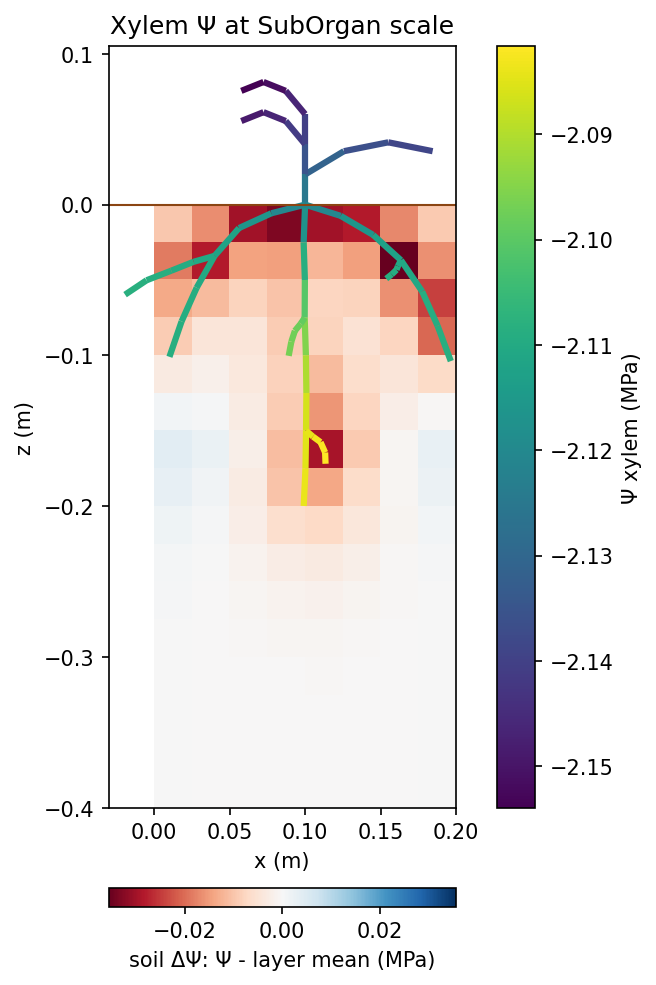

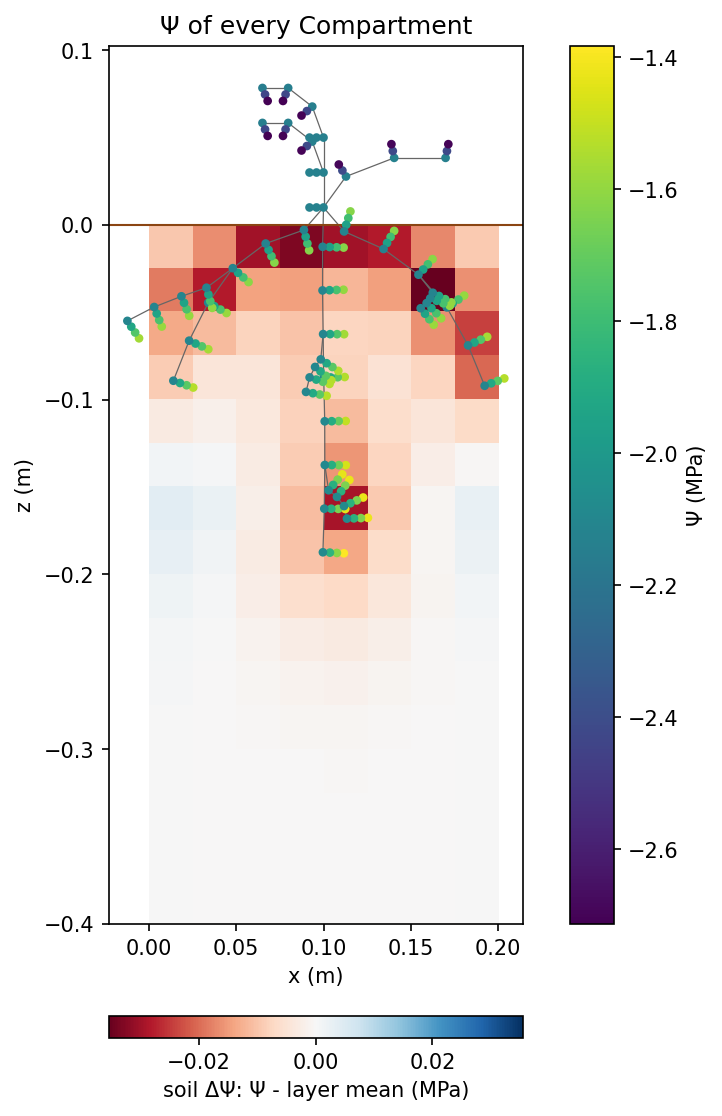

In [12]:
import os
from IPython.display import Image, display
import plotting

folder = "outputs/tutorial"
os.makedirs(folder, exist_ok=True)
plotting.plant_segments([plant], os.path.join(folder, "plant_segments_soil.png"), soil=soil)
plotting.plant_anatomy(plant, os.path.join(folder, "plant_anatomy_soil.png"), soil=soil)

for name in ("plant_segments_soil.png", "plant_anatomy_soil.png"):
    display(Image(filename=os.path.join(folder, name), width=600))